# Đề 8. Phân tích chi phí y tế cá nhân

**Mid-Term 2 · Nhóm 8**

Nhóm sử dụng tệp `insurance.csv` từ bộ [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance) để xem chi phí y tế khác nhau thế nào theo tình trạng hút thuốc, tuổi, BMI, giới tính, vùng và số con.

## 1. Thu thập và đánh giá dữ liệu ban đầu

In [ ]:
# --------------------------------------------------
# Phân tích chi phí y tế cá nhân - Medical Cost Personal Dataset (Đề 8)
# --------------------------------------------------
# Các bước thực hiện:
# Đọc và kiểm tra dữ liệu, làm sạch, sau đó phân tích bằng bảng và biểu đồ.


In [ ]:
# Các thư viện dùng trong bài
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
# Đọc file CSV từ GitHub của nhóm
url = "https://raw.githubusercontent.com/phongnt15ssc-lang/Midterm---Nh-m-8---KHDL-NEU/main/insurance.csv"
df_goc = pd.read_csv(url)
df = df_goc.copy()
print(df.head(10))
df.info()


   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
5   31  female  25.740         0     no  southeast   3756.62160
6   46  female  33.440         1     no  southeast   8240.58960
7   37  female  27.740         3     no  northwest   7281.50560
8   37    male  29.830         2     no  northeast   6406.41070
9   60  female  25.840         0     no  northwest  28923.13692
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   flo

In [ ]:
# Bảng 1: Xem kiểu dữ liệu, số ô thiếu và số giá trị khác nhau của mỗi cột
bang_1 = pd.DataFrame({"kieu": df.dtypes, "khong_thieu": df.notna().sum(),
                       "thieu_%": df.isna().mean() * 100, "so_gia_tri": df.nunique()})
print(bang_1)


             kieu  khong_thieu  thieu_%  so_gia_tri
age         int64         1338      0.0          47
sex        object         1338      0.0           2
bmi       float64         1338      0.0         548
children    int64         1338      0.0           6
smoker     object         1338      0.0           2
region     object         1338      0.0           4
charges   float64         1338      0.0        1337


In [ ]:
# Bảng 2: Xem các thống kê cơ bản của những cột dạng số
bang_2 = df.describe().round(2)
print(bang_2)


           age      bmi  children   charges
count  1338.00  1338.00   1338.00   1338.00
mean     39.21    30.66      1.09  13270.42
std      14.05     6.10      1.21  12110.01
min      18.00    15.96      0.00   1121.87
25%      27.00    26.30      0.00   4740.29
50%      39.00    30.40      1.00   9382.03
75%      51.00    34.69      2.00  16639.91
max      64.00    53.13      5.00  63770.43


In [ ]:
# Đếm số dòng thuộc từng nhóm
for cot in ["sex", "smoker", "region", "children"]:
    print(df[cot].value_counts(), "\n")


sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64 



In [ ]:
# Kiểm tra xem có dòng nào giống nhau hoàn toàn không
print("Số dòng trùng:", df.duplicated().sum())
print(df[df.duplicated(keep=False)])


Số dòng trùng: 1
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631


In [ ]:
# Với các dòng giống nhau hoàn toàn, giữ lại dòng đầu tiên
df = df.drop_duplicates().copy()
print(df.shape)


(1337, 7)


In [ ]:
# Kiểm tra các giá trị không hợp lý


In [ ]:
# Loại các dòng có tuổi, BMI hoặc chi phí không dương, hoặc số con âm
vo_ly = (df["age"] <= 0) | (df["bmi"] <= 0) | (df["charges"] <= 0) | (df["children"] < 0)
print("Số dòng vô lý:", vo_ly.sum())
df = df[~vo_ly].copy()
print(df.shape)


Số dòng vô lý: 0
(1337, 7)


In [ ]:
# Bảng 3: Tính cận IQR và đếm số giá trị nằm ngoài cận
def can_iqr(s):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    can_duoi = q1 - 1.5 * iqr
    can_tren = q3 + 1.5 * iqr
    return can_duoi, can_tren

dong = []
for cot in ["age", "bmi", "charges"]:
    duoi, tren = can_iqr(df[cot])
    so = ((df[cot] < duoi) | (df[cot] > tren)).sum()
    dong.append({"cot": cot, "can_duoi": round(duoi, 1), "can_tren": round(tren, 1),
                 "ngoai_le": so, "ty_le_%": round(so / len(df) * 100, 1)})
bang_3 = pd.DataFrame(dong)
print(bang_3)


       cot  can_duoi  can_tren  ngoai_le  ty_le_%
0      age      -9.0      87.0         0      0.0
1      bmi      13.7      47.3         9      0.7
2  charges  -13120.7   34524.8       139     10.4


In [ ]:
# Bảng 4: So sánh số chi phí ngoài cận khi xét cả mẫu và riêng từng nhóm hút thuốc
duoi, tren = can_iqr(df["charges"])
dong = []
for nhom in ["no", "yes"]:
    s = df.loc[df["smoker"] == nhom, "charges"]
    d, t = can_iqr(s)
    dong.append({"smoker": nhom, "so_nguoi": len(s), "nl_ca_mau": (s > tren).sum(),
                 "can_tren_nhom": round(t), "nl_trong_nhom": ((s < d) | (s > t)).sum()})
bang_4 = pd.DataFrame(dong)
print(bang_4)
print("Mean:", df["charges"].mean().round(0), "| Median:", round(df["charges"].median()))


  smoker  so_nguoi  nl_ca_mau  can_tren_nhom  nl_trong_nhom
0     no      1063          3          22424             46
1    yes       274        136          71309              0
Mean: 13279.0 | Median: 9386


In [ ]:
# Tìm các dòng có BMI nằm ngoài cận IQR
duoi_bmi, tren_bmi = can_iqr(df["bmi"])

bmi_thap = df["bmi"] < duoi_bmi
bmi_cao = df["bmi"] > tren_bmi
df["nl_bmi"] = bmi_thap | bmi_cao

print("Số điểm ngoài cận BMI:", df["nl_bmi"].sum())


Số điểm ngoài cận BMI: 9


In [ ]:
# Tìm chi phí ngoài cận IQR trong nhóm không hút thuốc
khong_hut = df["smoker"] == "no"
chi_phi_khong_hut = df.loc[khong_hut, "charges"]
duoi, tren = can_iqr(chi_phi_khong_hut)

chi_phi_thap = chi_phi_khong_hut < duoi
chi_phi_cao = chi_phi_khong_hut > tren

df["nl_chi_phi"] = False
df.loc[khong_hut, "nl_chi_phi"] = chi_phi_thap | chi_phi_cao


In [ ]:
# Làm tương tự với nhóm hút thuốc
co_hut = df["smoker"] == "yes"
chi_phi_co_hut = df.loc[co_hut, "charges"]
duoi, tren = can_iqr(chi_phi_co_hut)

chi_phi_thap = chi_phi_co_hut < duoi
chi_phi_cao = chi_phi_co_hut > tren
df.loc[co_hut, "nl_chi_phi"] = chi_phi_thap | chi_phi_cao

print("Số điểm ngoài cận chi phí:", df["nl_chi_phi"].sum())


Số điểm ngoài cận chi phí: 46


In [ ]:
# Đánh dấu dòng có BMI hoặc chi phí nằm ngoài cận
df["outlier"] = df["nl_bmi"] | df["nl_chi_phi"]

print("Ngoài cận BMI:", df["nl_bmi"].sum())
print("Ngoài cận chi phí:", df["nl_chi_phi"].sum())
print("Tổng số dòng được đánh dấu:", df["outlier"].sum())


Ngoài cận BMI: 9
Ngoài cận chi phí: 46
Tổng số dòng được đánh dấu: 55


In [ ]:
# Trong các dòng đã đánh dấu, xem 10 dòng có chi phí cao nhất
diem_ngoai_can = df[df["outlier"]]
diem_ngoai_can = diem_ngoai_can.sort_values("charges", ascending=False)
print(diem_ngoai_can.head(10))


      age     sex     bmi  children smoker     region      charges  nl_bmi  \
543    54  female  47.410         0    yes  southeast  63770.42801    True   
860    37  female  47.600         2    yes  southwest  46113.51100    True   
1047   22    male  52.580         1    yes  southeast  44501.39820    True   
1206   59  female  34.800         2     no  southwest  36910.60803   False   
1012   61  female  33.330         4     no  southeast  36580.28216   False   
242    55  female  26.800         1     no  southwest  35160.13457   False   
599    52  female  37.525         2     no  northwest  33471.97189   False   
936    44    male  29.735         2     no  northeast  32108.66282   False   
573    62  female  36.860         1     no  northeast  31620.00106   False   
387    50    male  25.365         2     no  northwest  30284.64294   False   

      nl_chi_phi  outlier  
543        False     True  
860        False     True  
1047       False     True  
1206        True     True  
1

In [ ]:
# Bảng 5: So sánh kết quả khi giữ và bỏ các dòng ngoài cận
df_loc = df[~df["outlier"]].copy()
bang_5 = pd.DataFrame({
    "Giu outlier (df)": [len(df), (df["smoker"] == "yes").mean() * 100, df["charges"].mean(),
                         df["charges"].median(), df.loc[df["smoker"] == "no", "charges"].median(),
                         df.loc[df["smoker"] == "yes", "charges"].median()],
    "Bo outlier (df_loc)": [len(df_loc), (df_loc["smoker"] == "yes").mean() * 100, df_loc["charges"].mean(),
                            df_loc["charges"].median(), df_loc.loc[df_loc["smoker"] == "no", "charges"].median(),
                            df_loc.loc[df_loc["smoker"] == "yes", "charges"].median()]},
    index=["so_dong", "ty_le_hut_thuoc_%", "trung_binh", "trung_vi", "trung_vi_khong_hut", "trung_vi_hut"]).round(1)
print(bang_5)


                    Giu outlier (df)  Bo outlier (df_loc)
so_dong                       1337.0               1282.0
ty_le_hut_thuoc_%               20.5                 21.1
trung_binh                   13279.1              12713.3
trung_vi                      9386.2               8967.1
trung_vi_khong_hut            7345.7               7144.9
trung_vi_hut                 34456.3              34303.2


In [ ]:
# Vẫn dùng df để phân tích vì chưa xác định các giá trị ngoài cận là lỗi.
print("Dữ liệu phân tích (df):", df.shape, "| Dữ liệu đã lọc outlier (df_loc):", df_loc.shape)


Dữ liệu phân tích (df): (1337, 10) | Dữ liệu đã lọc outlier (df_loc): (1282, 10)


In [ ]:
# Chia tuổi thành các nhóm 18–29, 30–39, 40–49 và 50–64
df["tuoi_nhom"] = "18-29"
df.loc[df["age"] >= 30, "tuoi_nhom"] = "30-39"
df.loc[df["age"] >= 40, "tuoi_nhom"] = "40-49"
df.loc[df["age"] >= 50, "tuoi_nhom"] = "50-64"


In [ ]:
# Chia BMI thành các nhóm để tiện so sánh
df["bmi_nhom"] = "1. Thieu can"
df.loc[df["bmi"] >= 18.5, "bmi_nhom"] = "2. Binh thuong"
df.loc[df["bmi"] >= 25, "bmi_nhom"] = "3. Thua can"
df.loc[df["bmi"] >= 30, "bmi_nhom"] = "4. Beo phi I"
df.loc[df["bmi"] >= 35, "bmi_nhom"] = "5. Beo phi II+"

df["beo_phi"] = "BMI < 30"
df.loc[df["bmi"] >= 30, "beo_phi"] = "BMI >= 30"


In [ ]:
# Gán hút thuốc là 1, không hút là 0 để tính tỷ lệ hút thuốc
df["hut"] = 0
df.loc[df["smoker"] == "yes", "hut"] = 1
print(df.head())


   age     sex     bmi  children smoker     region      charges  nl_bmi  \
0   19  female  27.900         0    yes  southwest  16884.92400   False   
1   18    male  33.770         1     no  southeast   1725.55230   False   
2   28    male  33.000         3     no  southeast   4449.46200   False   
3   33    male  22.705         0     no  northwest  21984.47061   False   
4   32    male  28.880         0     no  northwest   3866.85520   False   

   nl_chi_phi  outlier tuoi_nhom        bmi_nhom    beo_phi  hut  
0       False    False     18-29     3. Thua can   BMI < 30    1  
1       False    False     18-29    4. Beo phi I  BMI >= 30    0  
2       False    False     18-29    4. Beo phi I  BMI >= 30    0  
3       False    False     30-39  2. Binh thuong   BMI < 30    0  
4       False    False     30-39     3. Thua can   BMI < 30    0  


In [ ]:
# Đổi sex, smoker và region thành các cột 0/1 bằng one-hot
df_num = pd.get_dummies(df[["age", "sex", "bmi", "children", "smoker", "region", "charges"]],
                        columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
print(df_num.head())


   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400         0           1                 0   
1   18  33.770         1   1725.55230         1           0                 0   
2   28  33.000         3   4449.46200         1           0                 0   
3   33  22.705         0  21984.47061         1           0                 1   
4   32  28.880         0   3866.85520         1           0                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  


In [ ]:
# Bảng 6: So sánh chi phí giữa nhóm hút thuốc và không hút thuốc
bang_6 = df.groupby("smoker").agg(so_nguoi=("charges", "count"), trung_binh=("charges", "mean"),
                                  trung_vi=("charges", "median"))
print(bang_6.round(0))


        so_nguoi  trung_binh  trung_vi
smoker                                
no          1063      8441.0    7346.0
yes          274     32050.0   34456.0


In [ ]:
# Bảng 7: So sánh trung vị chi phí theo tuổi và hút thuốc
# Tính thêm tương quan giữa tuổi và chi phí
bang_7 = df.groupby(["tuoi_nhom", "smoker"])["charges"].median().unstack().round(0)
print(bang_7)
print("Tương quan toàn mẫu:", round(df["age"].corr(df["charges"]), 3))
for nhom in ["no", "yes"]:
    d = df[df["smoker"] == nhom]
    print("smoker =", nhom, ":", round(d["age"].corr(d["charges"]), 3))


smoker          no      yes
tuoi_nhom                  
18-29       2709.0  33604.0
30-39       5401.0  34113.0
40-49       8241.0  36450.0
50-64      12029.0  43696.0
Tương quan toàn mẫu: 0.298
smoker = no : 0.627
smoker = yes : 0.368


In [ ]:
# Bảng 8: So sánh chi phí theo hút thuốc và hai nhóm BMI dưới 30, từ 30 trở lên
# Tính thêm tương quan giữa BMI và chi phí
bang_8 = df.groupby(["smoker", "beo_phi"]).agg(so_nguoi=("charges", "count"), trung_vi=("charges", "median"),
                                              trung_binh=("charges", "mean")).round(0)
print(bang_8)
print("Tương quan toàn mẫu:", round(df["bmi"].corr(df["charges"]), 3))
for nhom in ["no", "yes"]:
    d = df[df["smoker"] == nhom]
    print("smoker =", nhom, ":", round(d["bmi"].corr(d["charges"]), 3))


                  so_nguoi  trung_vi  trung_binh
smoker beo_phi                                  
no     BMI < 30        502    6762.0      7977.0
       BMI >= 30       561    8084.0      8856.0
yes    BMI < 30        129   20167.0     21363.0
       BMI >= 30       145   40904.0     41558.0
Tương quan toàn mẫu: 0.198
smoker = no : 0.084
smoker = yes : 0.806


In [ ]:
# Bảng 9: Xem số người và trung vị chi phí theo nhóm BMI và hút thuốc
bang_9 = df.groupby(["bmi_nhom", "smoker"]).agg(so_nguoi=("charges", "count"),
                                               trung_vi=("charges", "median")).unstack().round(0)
print(bang_9)


               so_nguoi     trung_vi         
smoker               no yes       no      yes
bmi_nhom                                     
1. Thieu can         15   5   3733.0  15007.0
2. Binh thuong      175  50   6594.0  19480.0
3. Thua can         312  74   7064.0  21215.0
4. Beo phi I        316  74   7661.0  39086.0
5. Beo phi II+      245  71   8528.0  42970.0


In [ ]:
# Bảng 10: So sánh chi phí và tỷ lệ hút thuốc theo giới tính, vùng, số con
for cot in ["sex", "region", "children"]:
    bang_10 = df.groupby(cot).agg(so_nguoi=("charges", "count"), trung_binh=("charges", "mean"),
                                 trung_vi=("charges", "median"), hut_thuoc_pct=("hut", "mean"))
    bang_10["hut_thuoc_pct"] = bang_10["hut_thuoc_pct"] * 100
    print(bang_10.round(1), "\n")


        so_nguoi  trung_binh  trung_vi  hut_thuoc_pct
sex                                                  
female       662     12569.6    9413.0           17.4
male         675     13975.0    9377.9           23.6 

           so_nguoi  trung_binh  trung_vi  hut_thuoc_pct
region                                                  
northeast       324     13406.4   10057.7           20.7
northwest       324     12450.8    8977.0           17.9
southeast       364     14735.4    9294.1           25.0
southwest       325     12346.9    8798.6           17.8 

          so_nguoi  trung_binh  trung_vi  hut_thuoc_pct
children                                               
0              573     12384.7    9863.5           20.1
1              324     12731.2    8483.9           18.8
2              240     15073.6    9265.0           22.9
3              157     15355.3   10600.5           24.8
4               25     13850.7   11033.7           12.0
5               18      8786.0    8589.6      

In [ ]:
# Bảng 11: So sánh trung vị chi phí giữa các vùng, tách riêng hai nhóm hút thuốc
bang_11 = df.groupby(["region", "smoker"]).agg(so_nguoi=("charges", "count"),
                                              trung_vi=("charges", "median")).unstack().round(0)
print(bang_11)


          so_nguoi     trung_vi         
smoker          no yes       no      yes
region                                  
northeast      257  67   8343.0  28101.0
northwest      266  58   7259.0  27489.0
southeast      273  91   6653.0  37484.0
southwest      267  58   7348.0  35165.0


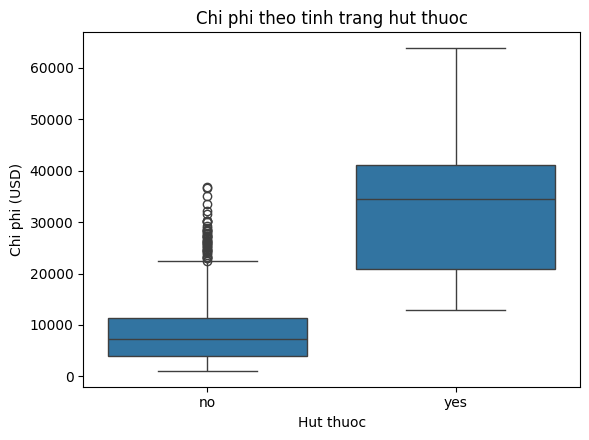

In [ ]:
# Hình 1: Dùng boxplot để so sánh chi phí của hai nhóm hút thuốc
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=df, x="smoker", y="charges", order=["no", "yes"], ax=ax)
ax.set(title="Chi phi theo tinh trang hut thuoc", xlabel="Hut thuoc", ylabel="Chi phi (USD)")
fig.tight_layout()
fig.savefig("hinh_1.png", dpi=200, bbox_inches="tight")
plt.show()


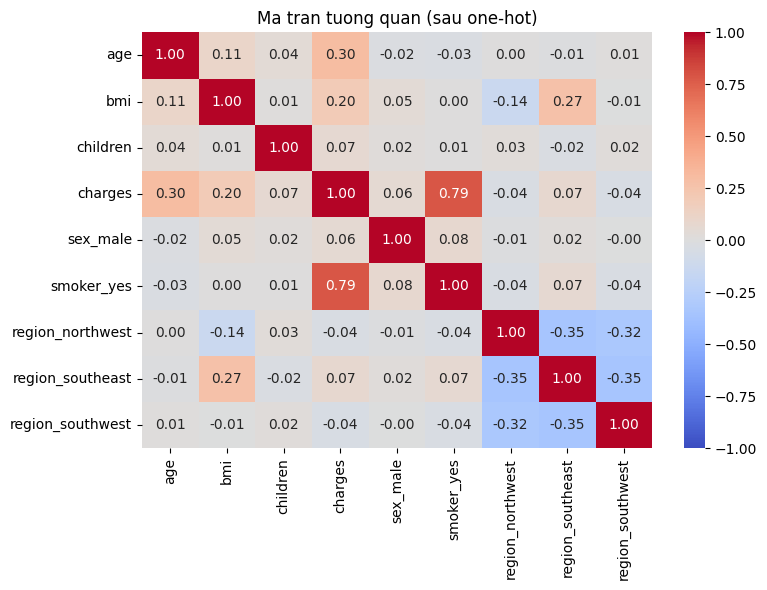

charges             1.000
smoker_yes          0.787
age                 0.298
bmi                 0.198
region_southeast    0.074
children            0.067
sex_male            0.058
region_northwest   -0.039
region_southwest   -0.044
Name: charges, dtype: float64


In [ ]:
# Hình 2: Vẽ heatmap tương quan sau khi đổi các cột phân loại thành 0/1
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Ma tran tuong quan (sau one-hot)")
fig.tight_layout()
fig.savefig("hinh_2.png", dpi=200, bbox_inches="tight")
plt.show()
print(df_num.corr()["charges"].sort_values(ascending=False).round(3))


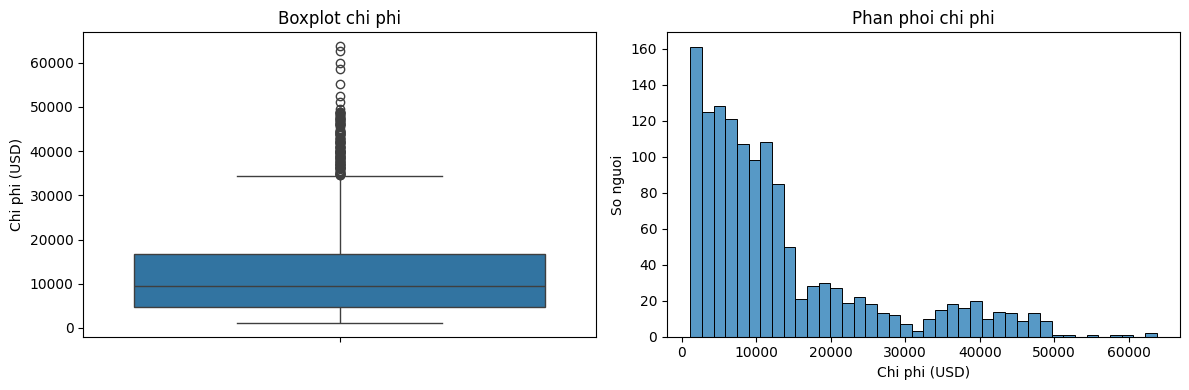

In [ ]:
# Hình 3: Xem phân bố chi phí bằng boxplot và histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df["charges"], ax=axes[0])
axes[0].set(title="Boxplot chi phi", ylabel="Chi phi (USD)")
sns.histplot(df["charges"], bins=40, ax=axes[1])
axes[1].set(title="Phan phoi chi phi", xlabel="Chi phi (USD)", ylabel="So nguoi")
fig.tight_layout()
fig.savefig("hinh_3.png", dpi=200, bbox_inches="tight")
plt.show()


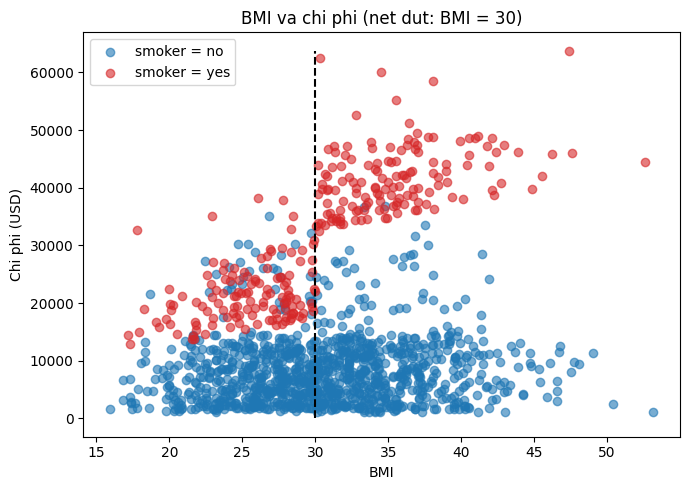

In [ ]:
# Hình 4: Vẽ BMI và chi phí, thêm đường nét đứt ở BMI = 30
fig, ax = plt.subplots(figsize=(7, 5))
for nhom, mau in [("no", "tab:blue"), ("yes", "tab:red")]:
    d = df[df["smoker"] == nhom]
    ax.scatter(d["bmi"], d["charges"], alpha=0.6, color=mau, label="smoker = " + nhom)
ax.plot([30, 30], [0, df["charges"].max()], "k--")
ax.legend()
ax.set(title="BMI va chi phi (net dut: BMI = 30)", xlabel="BMI", ylabel="Chi phi (USD)")
fig.tight_layout()
fig.savefig("hinh_4.png", dpi=200, bbox_inches="tight")
plt.show()


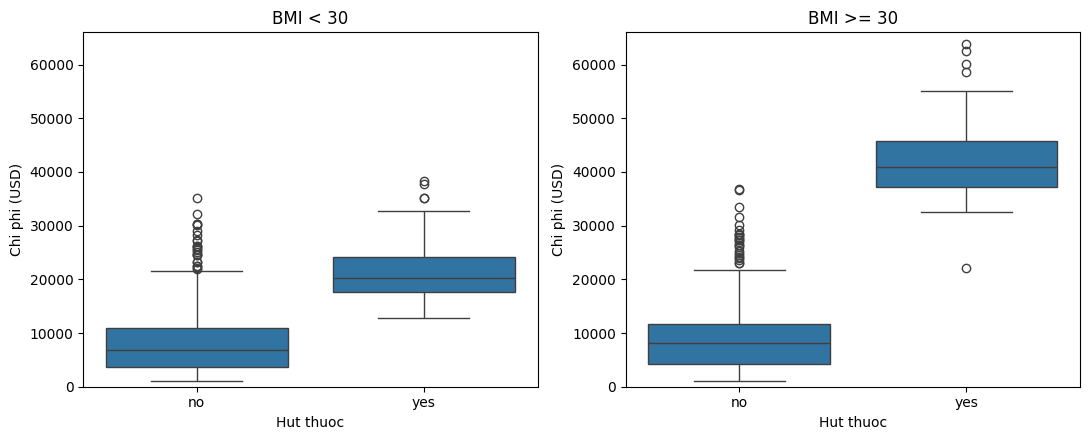

In [ ]:
# Hình 5: So sánh chi phí theo hút thuốc trong từng nhóm BMI
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, nhom in zip(axes, ["BMI < 30", "BMI >= 30"]):
    sns.boxplot(data=df[df["beo_phi"] == nhom], x="smoker", y="charges", order=["no", "yes"], ax=ax)
    ax.set(title=nhom, xlabel="Hut thuoc", ylabel="Chi phi (USD)", ylim=(0, 66000))
fig.tight_layout()
fig.savefig("hinh_5.png", dpi=200, bbox_inches="tight")
plt.show()


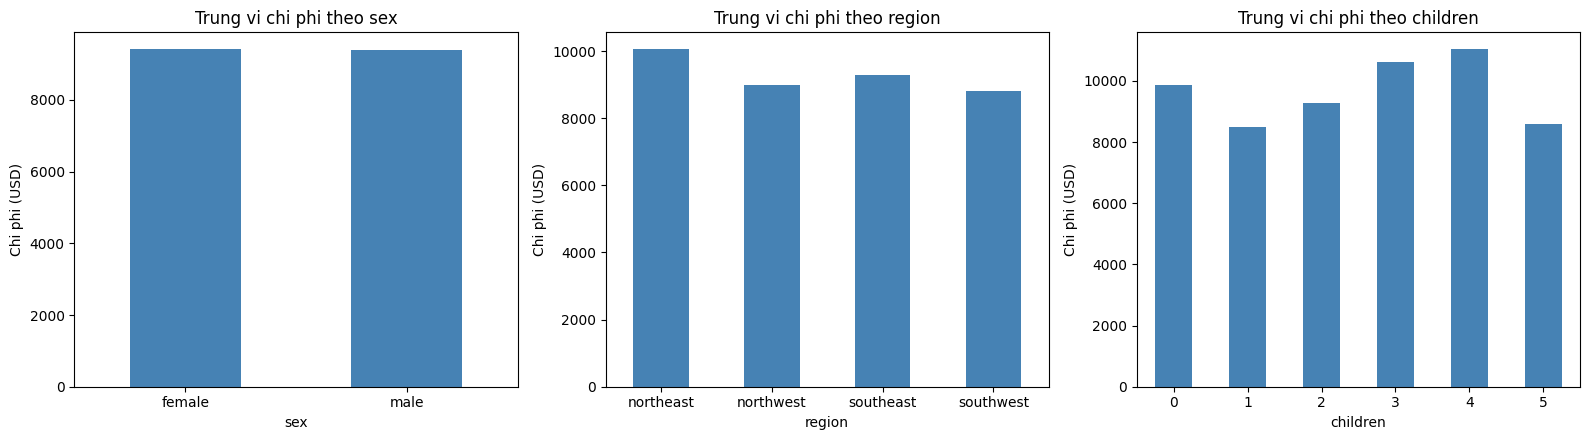

In [ ]:
# Hình 6: Vẽ cột trung vị chi phí theo giới tính, vùng và số con
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, cot in zip(axes, ["sex", "region", "children"]):
    df.groupby(cot)["charges"].median().plot.bar(ax=ax, rot=0, color="steelblue")
    ax.set(title="Trung vi chi phi theo " + cot, xlabel=cot, ylabel="Chi phi (USD)")
fig.tight_layout()
fig.savefig("hinh_6.png", dpi=200, bbox_inches="tight")
plt.show()


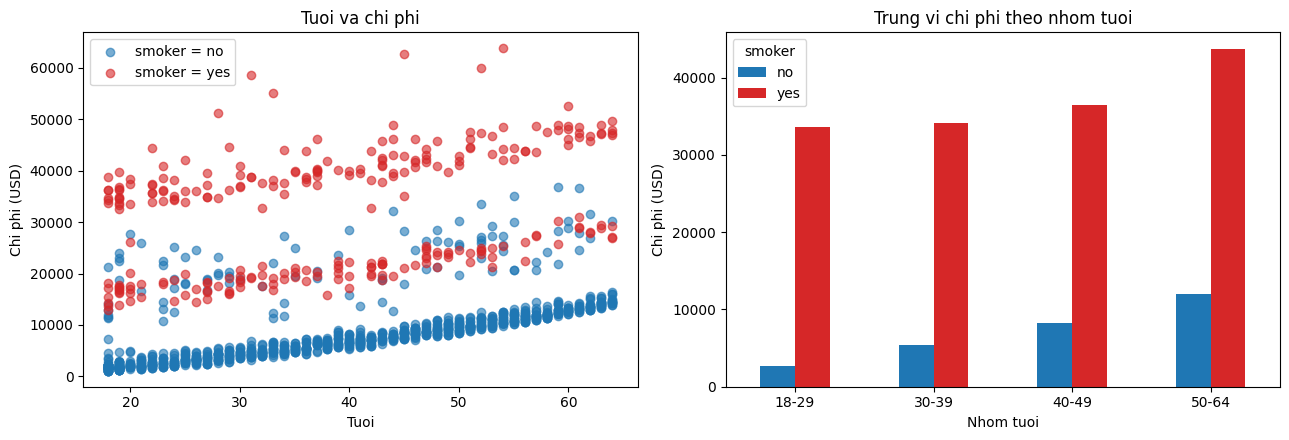

In [ ]:
# Hình 7: Vẽ tuổi và chi phí bên trái, trung vị theo nhóm tuổi bên phải
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nhom, mau in [("no", "tab:blue"), ("yes", "tab:red")]:
    d = df[df["smoker"] == nhom]
    axes[0].scatter(d["age"], d["charges"], alpha=0.6, color=mau, label="smoker = " + nhom)
axes[0].legend()
axes[0].set(title="Tuoi va chi phi", xlabel="Tuoi", ylabel="Chi phi (USD)")
bang_7.plot.bar(ax=axes[1], rot=0, color=["tab:blue", "tab:red"])
axes[1].set(title="Trung vi chi phi theo nhom tuoi", xlabel="Nhom tuoi", ylabel="Chi phi (USD)")
fig.tight_layout()
fig.savefig("hinh_7.png", dpi=200, bbox_inches="tight")
plt.show()


## 4. Kết quả và hướng phân tích tiếp

Hút thuốc cho thấy chênh lệch chi phí rõ nhất. Chi phí cũng tăng theo tuổi, còn chênh lệch theo BMI rõ hơn ở người hút thuốc. Có thể ưu tiên tìm hiểu nhu cầu hỗ trợ cai thuốc và quản lý cân nặng ở nhóm này. Dữ liệu thiếu thông tin bệnh nền và thời gian theo dõi, nên cần thêm dữ liệu để đánh giá tác động của các can thiệp.